In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys, re, random, time
import importlib
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_loaders
import miscellaneous

In [3]:
os.getcwd()

'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\sandbox'

In [4]:
data_root = '../data/KuaiRec2.0/data'

# User Features

In [5]:
user_features = pd.read_csv(os.path.join(data_root, 'user_features.csv'))

In [6]:
user_features.columns

Index(['user_id', 'user_active_degree', 'is_lowactive_period',
       'is_live_streamer', 'is_video_author', 'follow_user_num',
       'follow_user_num_range', 'fans_user_num', 'fans_user_num_range',
       'friend_user_num', 'friend_user_num_range', 'register_days',
       'register_days_range', 'onehot_feat0', 'onehot_feat1', 'onehot_feat2',
       'onehot_feat3', 'onehot_feat4', 'onehot_feat5', 'onehot_feat6',
       'onehot_feat7', 'onehot_feat8', 'onehot_feat9', 'onehot_feat10',
       'onehot_feat11', 'onehot_feat12', 'onehot_feat13', 'onehot_feat14',
       'onehot_feat15', 'onehot_feat16', 'onehot_feat17'],
      dtype='str')

In [7]:
user_features.head()

,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,...,onehot_feat8,onehot_feat9,onehot_feat10,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
0,0,high_active,0,0,0,5,"(0,10]",0,0,0,...,184,6,3,0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,full_active,0,0,0,386,"(250,500]",4,"[1,10)",2,...,186,6,2,0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,full_active,0,0,0,27,"(10,50]",0,0,0,...,51,2,3,0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,full_active,0,0,0,16,"(10,50]",0,0,0,...,251,3,2,0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,full_active,0,0,0,122,"(100,150]",4,"[1,10)",0,...,99,4,2,0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
user_features.describe()

,user_id,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,fans_user_num,friend_user_num,register_days,onehot_feat0,onehot_feat1,...,onehot_feat8,onehot_feat9,onehot_feat10,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
count,7176.000000,7176.000000,7176.000000,7176.000000,7176.000000,7176.000000,7176.000000,7176.000000,7176.000000,7176.000000,...,7176.000000,7176.000000,7176.000000,7176.000000,7099.000000,7101.000000,7101.000000,7102.000000,7102.000000,7102.000000
mean,3587.500000,0.000418,0.006828,0.169593,197.327899,12.553094,4.494844,296.790691,0.392280,2.670569,...,168.661511,3.831940,2.264353,0.137124,0.298774,0.104633,0.094775,0.018586,0.017882,0.014503
std,2071.677098,0.020444,0.082357,0.375301,426.543245,181.017537,44.897861,286.381320,0.488293,1.782502,...,96.254783,1.747046,1.063131,0.500184,0.457753,0.306102,0.292925,0.135068,0.132533,0.119560
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1793.750000,0.000000,0.000000,0.000000,9.000000,0.000000,0.000000,132.000000,0.000000,1.000000,...,88.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3587.500000,0.000000,0.000000,0.000000,33.000000,2.000000,0.000000,225.000000,0.000000,2.000000,...,167.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5381.250000,0.000000,0.000000,0.000000,130.000000,6.000000,1.000000,324.000000,1.000000,4.000000,...,255.000000,5.000000,3.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,7175.000000,1.000000,1.000000,1.000000,2100.000000,11401.000000,1425.000000,2245.000000,1.000000,7.000000,...,339.000000,6.000000,4.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## User ID

In [9]:
user_id = user_features['user_id']
user_id.nunique(), user_id.min(), user_id.max()

(7176, np.int64(0), np.int64(7175))

## Categorical Features

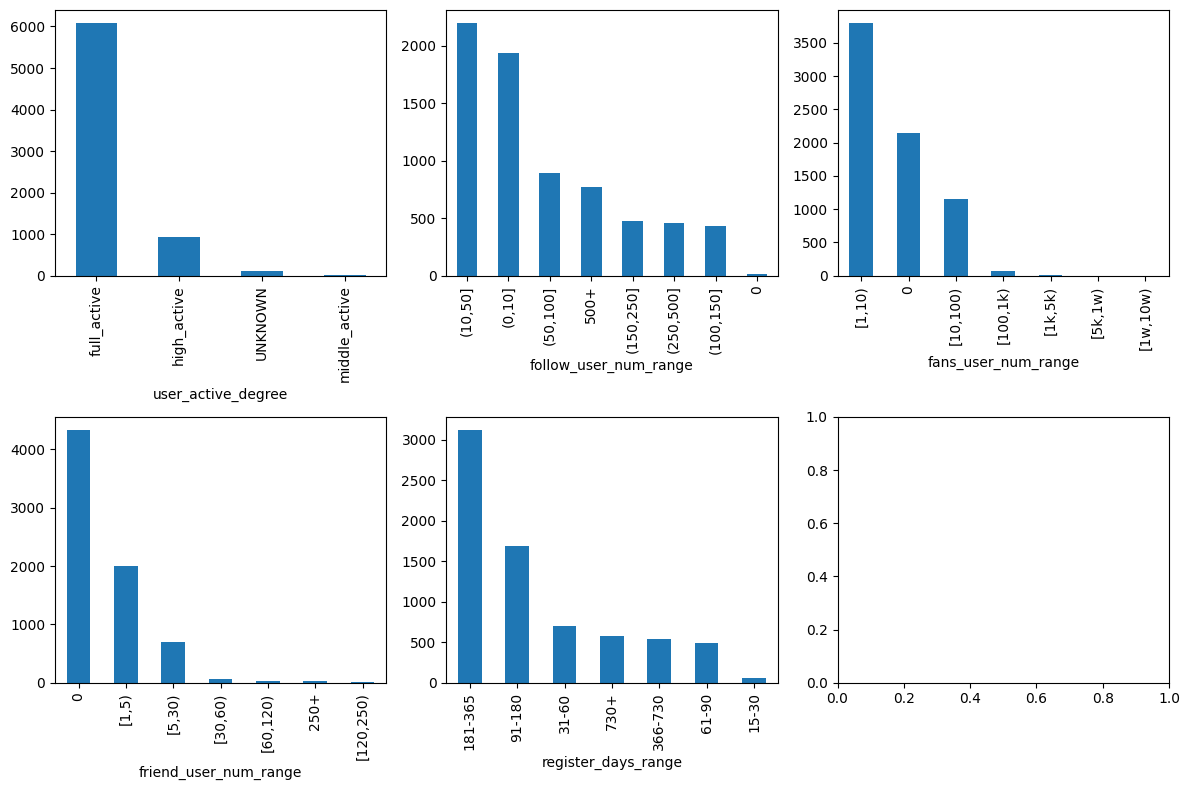

(None, None)

In [10]:
_, axs = plt.subplots(2, 3, figsize=(12, 8))
for col, ax in zip(['user_active_degree', 'follow_user_num_range', 'fans_user_num_range', 'friend_user_num_range', 'register_days_range'], axs.flatten()):
    user_features[col].value_counts().plot(kind='bar', ax=ax)
plt.tight_layout(), plt.show()

## Numerical Features

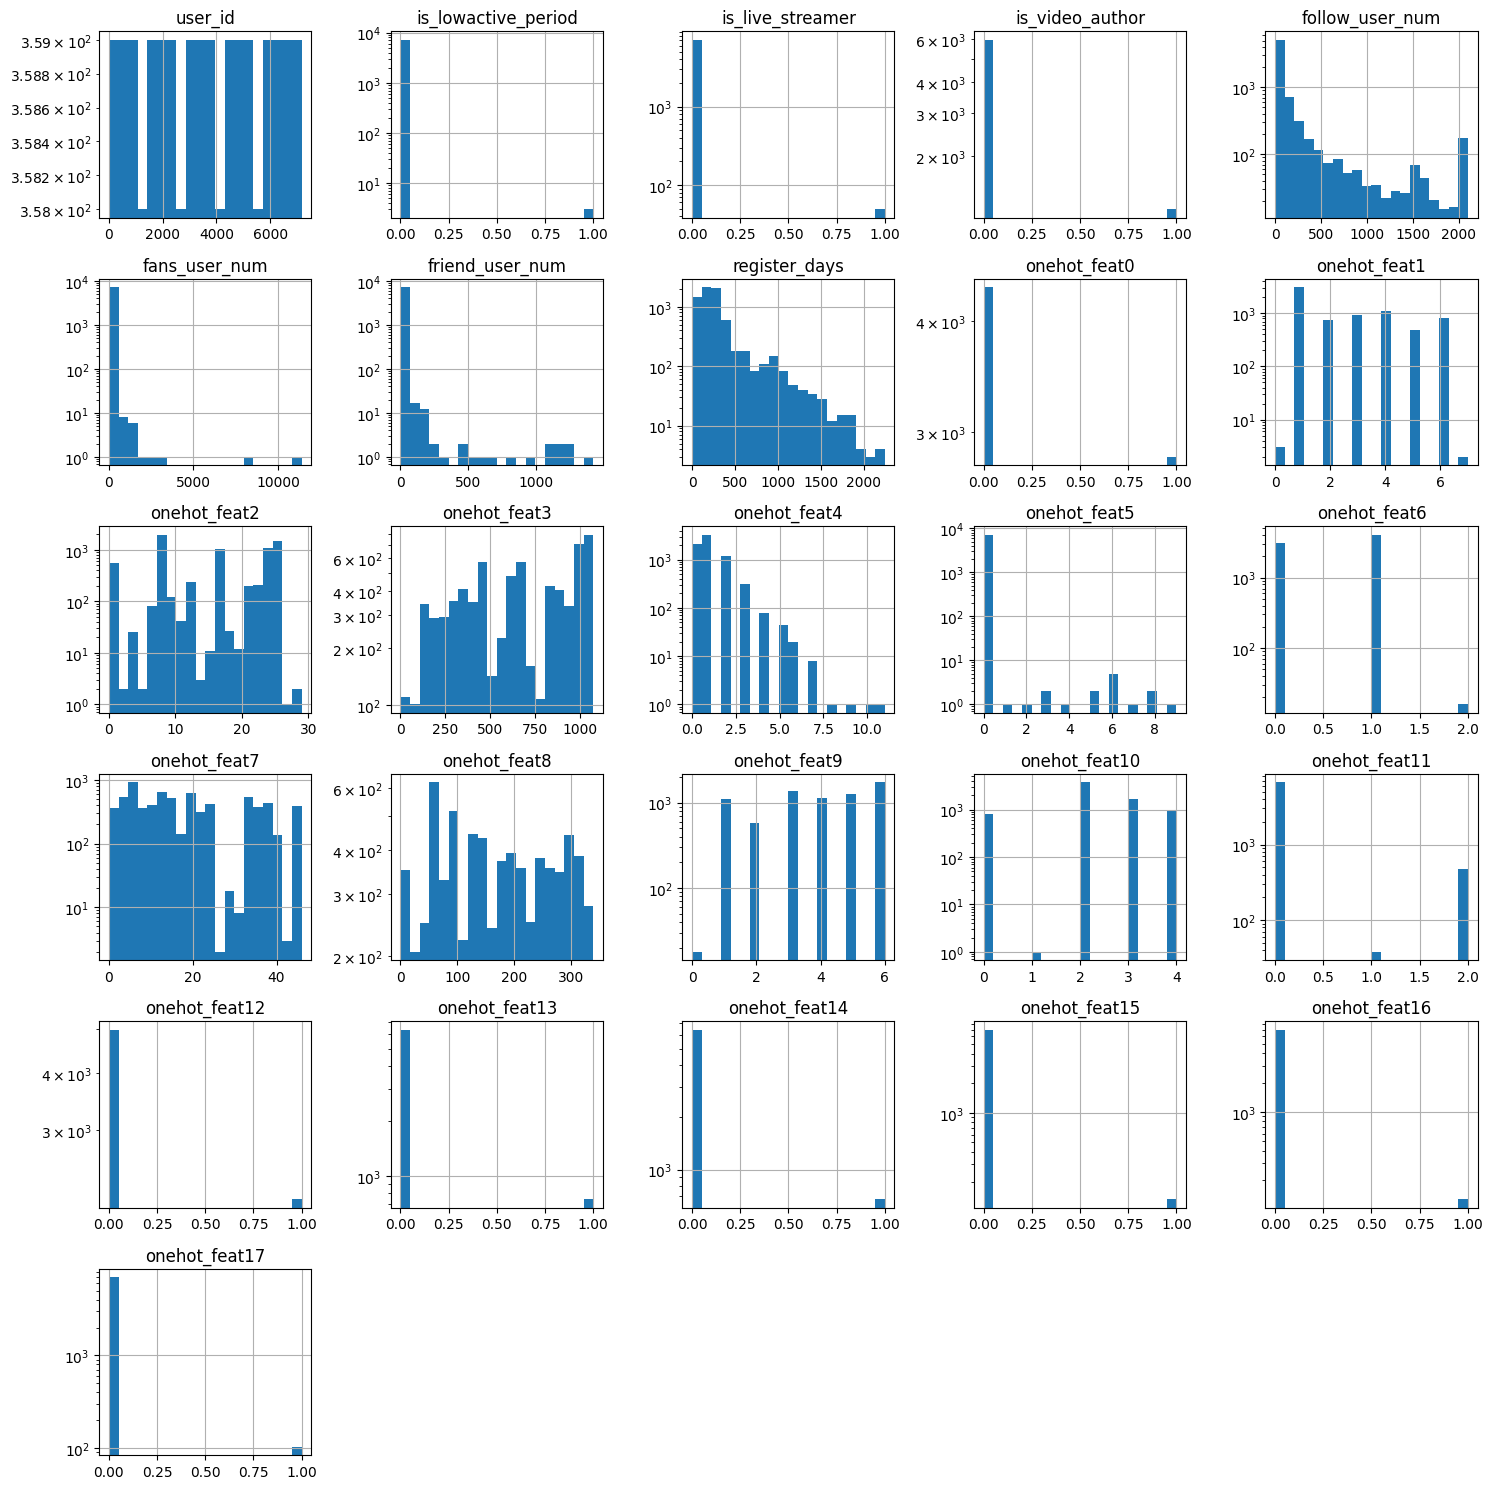

(None, None)

In [11]:
user_features.hist(bins=20, figsize=(15, 15), log=True)
plt.tight_layout(), plt.show()

In [12]:
useless_user_features = [
    'is_lowactive_period', 'is_live_streamer', 'is_video_author',
    'onehot_feat0', 'onehot_feat12', 'onehot_feat13', 'onehot_feat14',
    'onehot_feat15', 'onehot_feat16', 'onehot_feat17',
]

# Item Features

In [13]:
item_categories = pd.read_csv(os.path.join(data_root, 'item_categories.csv'))
kuairec_caption_category = pd.read_csv(os.path.join(data_root, 'kuairec_caption_category.csv'), engine='python')

In [14]:
item_categories.columns

Index(['video_id', 'feat'], dtype='str')

In [15]:
item_categories.head()

,video_id,feat
0,0,[8]
1,1,"[27, 9]"
2,2,[9]
3,3,[26]
4,4,[5]


In [16]:
item_categories.describe()

,video_id
count,10728.000000
mean,5363.500000
std,3097.051178
min,0.000000
25%,2681.750000
50%,5363.500000
75%,8045.250000
max,10727.000000


In [17]:
kuairec_caption_category.columns

Index(['video_id', 'manual_cover_text', 'caption', 'topic_tag',
       'first_level_category_id', 'first_level_category_name',
       'second_level_category_id', 'second_level_category_name',
       'third_level_category_id', 'third_level_category_name'],
      dtype='str')

In [18]:
kuairec_caption_category.head()

,video_id,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
0,0,UNKNOWN,精神小伙路难走 程哥你狗粮慢点撒,[],8,颜值,673,颜值随拍,-124,UNKNOWN
1,1,UNKNOWN,NaN,[],27,高新数码,-124,UNKNOWN,-124,UNKNOWN
2,2,UNKNOWN,晚饭后，运动一下！,[],9,喜剧,727,搞笑互动,-124,UNKNOWN
3,3,UNKNOWN,我平淡无奇，惊艳不了时光，温柔不了岁月，我只想漫无目的的走走，努力发笔小财，给自己买花 自己长大.,[],26,摄影,686,主题摄影,2434,景物摄影
4,4,五爱街最美美女 一天1q,#搞笑 #感谢快手我要上热门 #五爱市场 这真是完美搭配啊！,"[五爱市场,感谢快手我要上热门,搞笑]",5,时尚,737,营销售卖,2596,女装


In [19]:
kuairec_caption_category.describe()

,video_id,first_level_category_id,second_level_category_id,third_level_category_id
count,10728.000000,10728.000000,10728.000000,10728.000000
mean,5363.500000,16.545302,266.552386,661.374720
std,3097.051178,13.966887,340.920778,1104.046033
min,0.000000,-124.000000,-124.000000,-124.000000
25%,2681.750000,7.000000,-124.000000,-124.000000
50%,5363.500000,15.000000,223.000000,-124.000000
75%,8045.250000,28.000000,681.250000,1524.000000
max,10727.000000,39.000000,749.000000,2676.000000


## Categorical Features

<Axes: ylabel='Frequency'>

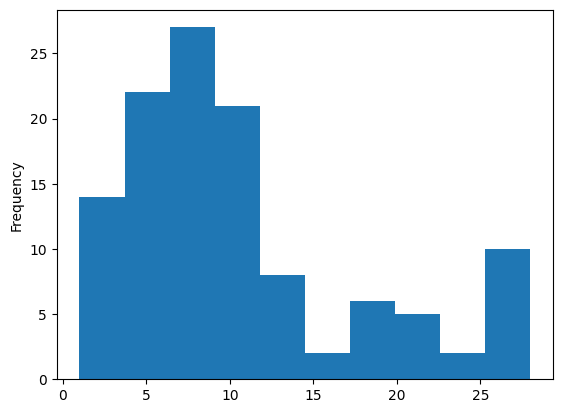

In [20]:
feature_flattened = item_categories.iloc[:100]['feat'].map(lambda x: x[1:-1].split(', ')).explode().map(int)
feature_flattened.plot(kind='hist')

In [21]:
feature_flattened.min(), feature_flattened.max()

(np.int64(1), np.int64(28))

## Numerical Features

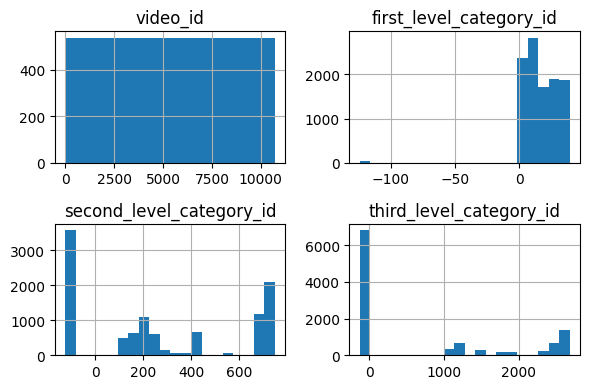

(None, None)

In [22]:
kuairec_caption_category.hist(bins=20, figsize=(6, 4))
plt.tight_layout(), plt.show()

In [23]:
topic_tags = kuairec_caption_category['topic_tag'].map(lambda x: x[1:-1].split(',')).explode()

In [24]:
topic_tags.nunique()

6060

In [25]:
topic_tags.value_counts()

topic_tag
               4611
感谢快手我要上热门       975
作品推广            824
快手创作者服务中心       490
感谢快手官大大送上热门     417
               ... 
洗车机               1
高压洗车机             1
2020新款            1
原创视频              1
民族复古风             1
Name: count, Length: 6060, dtype: int64

In [26]:
# TODO: Maybe we can take only the most used tags and OHE them

<Axes: xlabel='topic_tag'>

C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\IPython\core\events.py:100: UserWarning: Glyph 24863 (\N{CJK UNIFIED IDEOGRAPH-611F}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\IPython\core\events.py:100: UserWarning: Glyph 35874 (\N{CJK UNIFIED IDEOGRAPH-8C22}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\IPython\core\events.py:100: UserWarning: Glyph 24555 (\N{CJK UNIFIED IDEOGRAPH-5FEB}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\IPython\core\events.py:100: UserWarning: Glyph 25163 (\N{CJK UNIFIED IDEOGRAPH-624B}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\IPython\core\events.py:100: UserWarning: Glyph 25105 (\N{CJK UNIFIED IDEOG

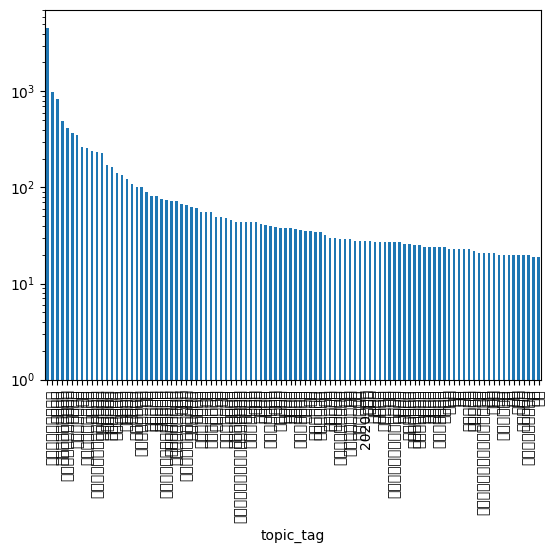

In [27]:
topic_tags.value_counts()[:100].plot(kind='bar', log=True)

# Small Matrix

In [28]:
small_matrix = pd.read_csv(os.path.join(data_root, 'small_matrix.csv'))

In [29]:
small_matrix.columns

Index(['user_id', 'video_id', 'play_duration', 'video_duration', 'time',
       'date', 'timestamp', 'watch_ratio'],
      dtype='str')

In [30]:
small_matrix.head()

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364


In [31]:
small_matrix.describe()

,user_id,video_id,play_duration,video_duration,date,timestamp,watch_ratio
count,4.676570e+06,4.676570e+06,4.676570e+06,4.676570e+06,4.494578e+06,4.494578e+06,4.676570e+06
mean,3.631649e+03,4.974939e+03,8.612637e+03,1.448645e+04,2.020077e+07,1.596241e+09,9.070695e-01
std,2.043873e+03,3.064622e+03,1.223661e+04,2.046711e+04,4.895180e+01,1.254444e+06,1.362324e+00
min,1.400000e+01,1.030000e+02,0.000000e+00,3.067000e+03,2.020070e+07,1.593801e+09,0.000000e+00
25%,1.834000e+03,2.369000e+03,5.811000e+03,7.523000e+03,2.020072e+07,1.595210e+09,4.675769e-01
50%,3.687000e+03,4.692000e+03,7.549000e+03,9.600000e+03,2.020080e+07,1.596224e+09,7.691666e-01
75%,5.421000e+03,7.474000e+03,9.880000e+03,1.193400e+04,2.020081e+07,1.597121e+09,1.120590e+00
max,7.162000e+03,1.059500e+04,7.988155e+06,3.150720e+05,2.020090e+07,1.599321e+09,5.715214e+02


In [32]:
small_matrix['time'] = pd.to_datetime(small_matrix['time'])

In [33]:
small_matrix['user_id'].nunique(), small_matrix['video_id'].nunique()

(1411, 3327)

<Axes: xlabel='user_id'>

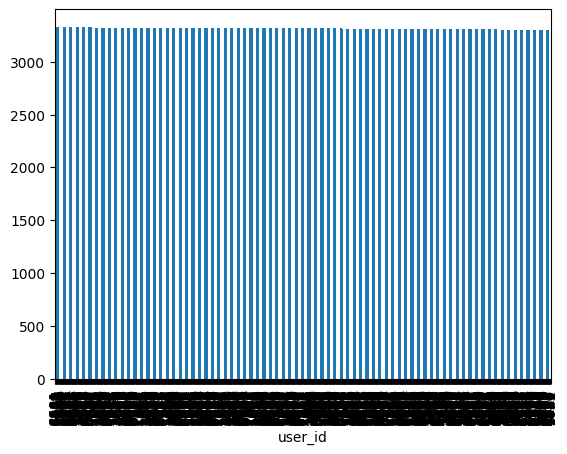

In [139]:
small_matrix['user_id'].value_counts().plot(kind='bar')

<Axes: xlabel='video_id'>

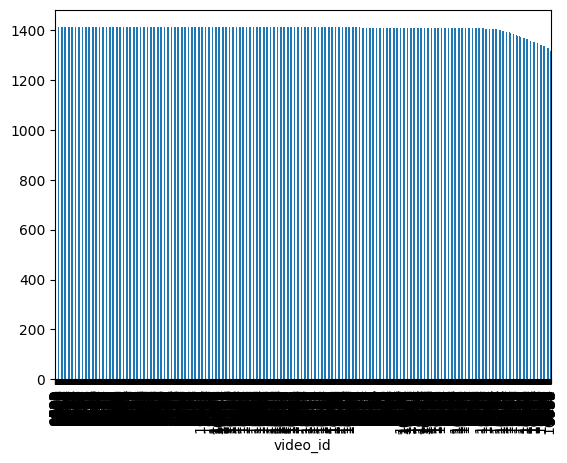

In [140]:
small_matrix['video_id'].value_counts().plot(kind='bar')

In [49]:
len(small_matrix)

4676570

In [50]:
smaller_matrix = miscellaneous.balanced_subset(small_matrix, 1000000)

k_u (per user): 708, k_i (per item): 300


In [51]:
smaller_matrix

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,3868,9914,13001,7967,2020-07-30 09:15:45.341,20200730.0,1.596072e+09,1.631856
1,6026,8562,9851,6734,2020-07-19 14:54:19.330,20200719.0,1.595142e+09,1.462875
2,6154,4677,6878,10221,NaT,NaN,NaN,0.672928
3,3458,4270,5601,8300,2020-08-04 09:08:50.196,20200804.0,1.596503e+09,0.674819
4,5660,8819,9078,6100,2020-08-03 06:33:25.039,20200803.0,1.596408e+09,1.488197
...,...,...,...,...,...,...,...,...
998095,2839,10260,8922,50721,2020-08-09 01:34:31.869,20200809.0,1.596908e+09,0.175903
998096,7122,457,7501,8242,2020-07-11 23:02:52.222,20200711.0,1.594480e+09,0.910095
998097,1898,8594,5568,8600,2020-07-28 17:04:12.460,20200728.0,1.595927e+09,0.647442
998098,4914,698,18973,10906,2020-07-24 02:15:05.764,20200724.0,1.595528e+09,1.739685


In [52]:
# should be (1411, 3327)
smaller_matrix['user_id'].nunique(), smaller_matrix['video_id'].nunique()

(1411, 3327)

In [55]:
del smaller_matrix, small_matrix

In [56]:
import gc
gc.collect()

177

<Axes: xlabel='user_id'>

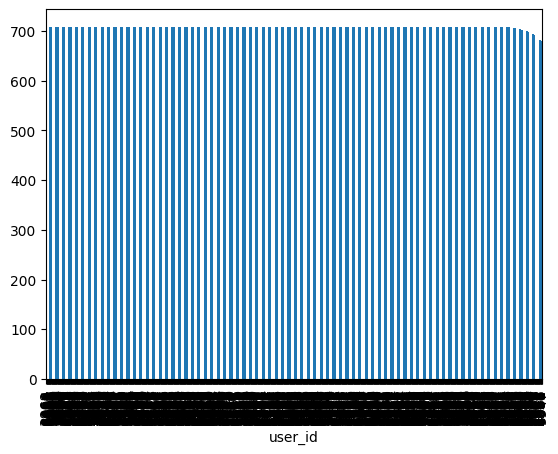

In [53]:
smaller_matrix['user_id'].value_counts().plot(kind='bar')

<Axes: xlabel='video_id'>

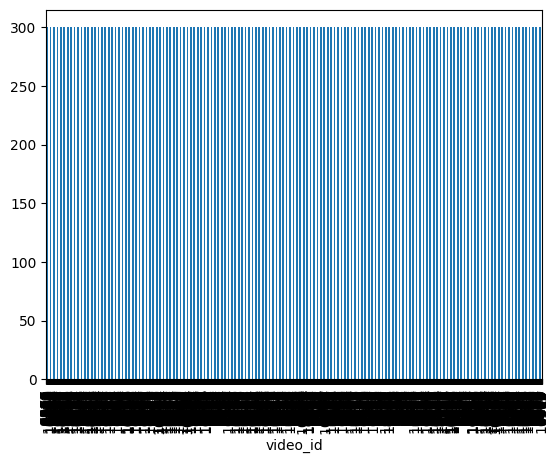

In [54]:
smaller_matrix['video_id'].value_counts().plot(kind='bar')

# Do all users start off in the same time range?

In [134]:
starting_times = small_matrix.groupby('user_id')['time'].min()
print("MIN", starting_times.min())
print("MIN", starting_times.max())
print("RAN", starting_times.max() - starting_times.min())
print("STD", starting_times.std())

MIN 2020-07-04 02:23:26.060000
MIN 2020-07-17 12:42:50.496000
RAN 13 days 10:19:24.436000
STD 0 days 19:17:28.137560


# Just trying to detect if there are temporal dependencies like change in pref over time

In [117]:
small_matrix['user_id'].value_counts()[::-1]

user_id
5742    3295
1853    3295
4427    3296
3246    3296
1226    3296
        ... 
5339    3327
5149    3327
4681    3327
3201    3327
1834    3327
Name: count, Length: 1411, dtype: int64

In [118]:
user_1834 = small_matrix[small_matrix['user_id'] == 5742]
user_1834.sort_values(by='time')

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
3774956,5742,1963,17493,9590,2020-07-05 07:27:48.038,20200705.0,1.593905e+09,1.824088
3774957,5742,5262,2477,7908,2020-07-05 07:50:10.300,20200705.0,1.593907e+09,0.313227
3774958,5742,179,12776,6067,2020-07-05 08:33:19.860,20200705.0,1.593909e+09,2.105818
3774959,5742,1933,3670,7200,2020-07-05 09:08:47.765,20200705.0,1.593911e+09,0.509722
3774960,5742,148,1651,6067,2020-07-05 09:48:41.729,20200705.0,1.593914e+09,0.272128
...,...,...,...,...,...,...,...,...
3778246,5742,2582,5725,8701,NaT,NaN,NaN,0.657970
3778247,5742,378,34552,6167,NaT,NaN,NaN,5.602724
3778248,5742,5567,8257,9472,NaT,NaN,NaN,0.871727
3778249,5742,10271,13488,139134,NaT,NaN,NaN,0.096943


In [125]:
user_1834['time'].min(), user_1834['time'].max()

(Timestamp('2020-07-05 07:27:48.038000'),
 Timestamp('2020-09-05 06:22:39.819000'))

In [119]:
item_to_feats = item_categories['feat'].map(lambda x: list(map(int, x[1:-1].split(', '))))

In [120]:
item_feat_ohe = pd.DataFrame(index=item_to_feats.index)

In [121]:
for i in range(1, 29):
    item_feat_ohe[f'feat_{i}'] = item_to_feats.map(lambda x: i in x)

In [122]:
user_prefs = item_feat_ohe.iloc[user_1834['video_id']]

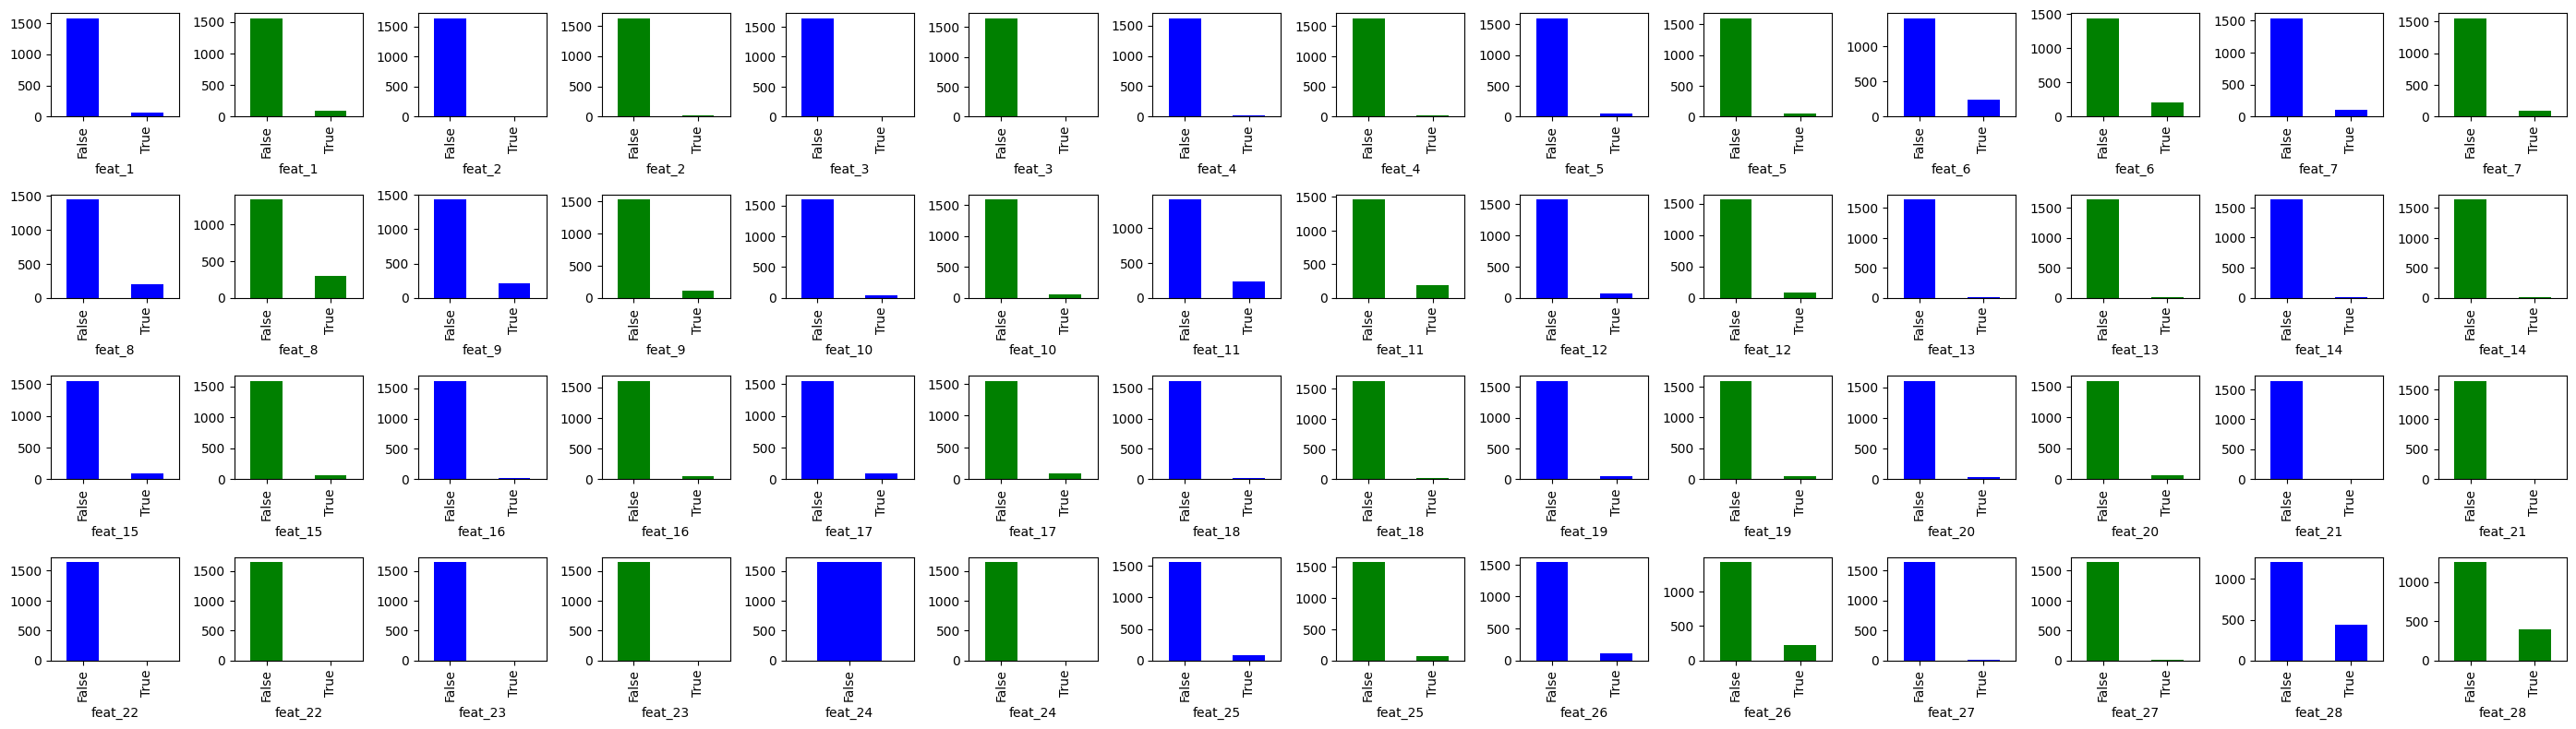

In [155]:
_, axs = plt.subplots(4, 14, figsize=(28, 8))
for i, ax in enumerate(axs.flatten()):
    if i % 2 == 0: user_prefs.iloc[:len(user_prefs) // 2][f'feat_{1 + i // 2}'].value_counts().plot(kind='bar', ax=ax, color='b')
    else: user_prefs.iloc[len(user_prefs) // 2:][f'feat_{1 + i // 2}'].value_counts().plot(kind='bar', ax=ax, color='g')
plt.tight_layout()

In [192]:
dist_left = []
dist_right = []
for user_id in small_matrix['user_id'].unique():
    user_prefs = item_feat_ohe.iloc[small_matrix[small_matrix['user_id'] == user_id]['video_id']]
    dist_left_col = []
    dist_right_col = []
    for feat in user_prefs.columns:
        lll = len(user_prefs)
        dist = user_prefs[feat][:lll // 3].mean()
        dist_left_col.append(dist)
        dist = user_prefs[feat][-lll // 3:].mean()
        dist_right_col.append(dist)
    dist_left.append(np.asarray(dist_left_col) / np.sum(dist_left_col))
    dist_right.append(np.asarray(dist_right_col) / np.sum(dist_right_col))

In [194]:
# dist_left, dist_right

In [182]:
from scipy.spatial.distance import jensenshannon

In [196]:
drift = []
for left, right in zip(dist_left, dist_right):
    drift.append(jensenshannon(left, right) ** 2)

In [198]:
print("mean:", np.mean(drift))
print("median:", np.median(drift))
print("p90:", np.percentile(drift, 90))
print("max:", np.max(drift))

mean: 0.015298769269498838
median: 0.014555074306712629
p90: 0.02060128856234757
max: 0.04559569179763978


In [157]:
len(item_feat_ohe)

10728

In [158]:
len(small_matrix)

4676570